ConvNeXtV2

In [ ]:
import os
import json
import random
import shutil
import zipfile
from collections import Counter

import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms

# =====================================================================
# Step 1: Mount Google Drive (uncomment if not mounted yet)
# =====================================================================
# from google.colab import drive
# drive.mount('/content/drive')

# =====================================================================
# Step 2: Copy zip to local disk and extract (much faster than reading Drive)
# =====================================================================
ZIP_ON_DRIVE = "/content/drive/MyDrive/CSC490_data/d2c_v3.zip"
LOCAL_ZIP = "/content/d2c_v3.zip"
EXTRACT_TO = "/content"
DATA_ROOT = "/content/d2c_v2"          # top-level folder inside the zip

INCLUDE_BENIGN = True                  # False = experiment A, True = experiment B
DATASET_JSON = "master_dataset_with_benign.json" if INCLUDE_BENIGN else "master_dataset.json"

if not os.path.exists(os.path.join(DATA_ROOT, "master_dataset_with_benign.json")):
    print("Copying zip to local disk...")
    shutil.copy(ZIP_ON_DRIVE, LOCAL_ZIP)
    print("Extracting...")
    with zipfile.ZipFile(LOCAL_ZIP, "r") as z:
        z.extractall(EXTRACT_TO)
print("Data ready at", DATA_ROOT)

# =====================================================================
# Step 3: Label maps
# =====================================================================
FAMILY_MAP = {"typography": 0, "colour": 1, "appearance": 2, "shape": 3, "layout": 4}
OPERATOR_MAP = {
    "font_size": 0, "font_weight": 1, "line_height": 2, "letter_spacing": 3,
    "text_color": 4, "background_color": 5, "opacity": 6,
    "border_radius": 7, "border_width": 8,
    "padding": 9, "margin": 10, "position": 11, "width": 12,
}
IGNORE = -100  # class targets for negatives; use CrossEntropyLoss(ignore_index=-100)

TRAIN_RATIO = 0.85
SPLIT_SEED = 490


def make_grouped_split(root, train_ratio=TRAIN_RATIO, seed=SPLIT_SEED):
    """A page and ALL of its variants always land in the same set (grouped by parent_id)."""
    with open(os.path.join(root, DATASET_JSON), encoding="utf-8") as f:
        recs = json.load(f)
    print(f"loaded {DATASET_JSON}: {len(recs)} pairs")

    pages = sorted({r["parent_id"] for r in recs})
    random.Random(seed).shuffle(pages)
    n_train = int(round(train_ratio * len(pages)))
    train_pages = set(pages[:n_train])

    train_recs = [r for r in recs if r["parent_id"] in train_pages]
    val_recs = [r for r in recs if r["parent_id"] not in train_pages]

    overlap = {r["parent_id"] for r in train_recs} & {r["parent_id"] for r in val_recs}
    assert not overlap, f"leakage: {len(overlap)} pages in both splits"

    for name, rs in [("train", train_recs), ("val", val_recs)]:
        n_pages = len({r["parent_id"] for r in rs})
        print(f"[{name}] {n_pages} pages | {len(rs)} pairs | labels: {dict(Counter(r['label'] for r in rs))}")
    return train_recs, val_recs


# =====================================================================
# Step 4: Dataset
# =====================================================================
class PairedUIRegressionDataset(Dataset):
    """
    Returns (reference, candidate) image pairs.

    mode="tile": crop the SAME window from both images at native resolution.
        - regression: window placed around the mutated element (bbox), with random jitter
        - negatives : random window inside the height both images share
    mode="full": resize the whole page to full_size (small changes may disappear).
    """

    def __init__(self, records, root, mode="tile", tile=512, full_size=(448, 448),
                 jitter=True, transform=None):
        self.records = records
        self.root = root
        self.mode = mode
        self.tile = tile
        self.full_size = full_size
        self.jitter = jitter
        self.transform = transform or transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

    def __len__(self):
        return len(self.records)

    @staticmethod
    def _pad_to(img, W, H):
        """Pad with white so both images share the same canvas."""
        if img.size == (W, H):
            return img
        canvas = Image.new("RGB", (W, H), "white")
        canvas.paste(img, (0, 0))
        return canvas

    def _target_box(self, r):
        """Union of bbox before/after, i.e. where the change lives."""
        b0, b1 = r.get("bbox_before"), r.get("bbox_after")
        if not b0 or not b1:
            return None
        x0 = min(b0[0], b1[0]); y0 = min(b0[1], b1[1])
        x1 = max(b0[0] + b0[2], b1[0] + b1[2]); y1 = max(b0[1] + b0[3], b1[1] + b1[3])
        return x0, y0, x1, y1

    def _choose_window(self, r, W, H, H_common):
        T = self.tile
        box = self._target_box(r) if r["label"] == "regression" else None
        if box is None:
            # negatives: stay inside the height both images share (never crop the white padding)
            x = random.randint(0, max(0, W - T))
            y = random.randint(0, max(0, min(H, H_common) - T))
            return x, y
        cx, cy = (box[0] + box[2]) / 2, (box[1] + box[3]) / 2
        if self.jitter:  # so the change is not always dead-centre
            cx += random.uniform(-T / 4, T / 4)
            cy += random.uniform(-T / 4, T / 4)
        x = int(min(max(0, cx - T / 2), max(0, W - T)))
        y = int(min(max(0, cy - T / 2), max(0, H - T)))
        return x, y

    def __getitem__(self, idx):
        r = self.records[idx]
        ref = Image.open(os.path.join(self.root, r["reference_path"])).convert("RGB")
        cand = Image.open(os.path.join(self.root, r["candidate_path"])).convert("RGB")

        H_common = min(ref.height, cand.height)   # measured BEFORE padding
        W, H = max(ref.width, cand.width), max(ref.height, cand.height)
        ref, cand = self._pad_to(ref, W, H), self._pad_to(cand, W, H)

        if self.mode == "tile":
            T = self.tile
            if W < T or H < T:  # tiny page: pad up to one tile
                W2, H2 = max(W, T), max(H, T)
                ref, cand = self._pad_to(ref, W2, H2), self._pad_to(cand, W2, H2)
                W, H = W2, H2
            x, y = self._choose_window(r, W, H, H_common)
            ref = ref.crop((x, y, x + T, y + T))
            cand = cand.crop((x, y, x + T, y + T))
        else:
            ref = ref.resize(self.full_size, Image.BILINEAR)
            cand = cand.resize(self.full_size, Image.BILINEAR)

        is_reg = r["label"] == "regression"
        return {
            "img_ref": self.transform(ref),
            "img_cand": self.transform(cand),
            "is_regression": torch.tensor(1.0 if is_reg else 0.0),
            "family": torch.tensor(FAMILY_MAP[r["family"]] if is_reg else IGNORE),
            "operator": torch.tensor(OPERATOR_MAP[r["operator"]] if is_reg else IGNORE),
            "sample_id": r["sample_id"],
        }


# =====================================================================
# Step 5: Loaders + class balance
# =====================================================================
train_recs, val_recs = make_grouped_split(DATA_ROOT)

train_ds = PairedUIRegressionDataset(train_recs, DATA_ROOT, mode="tile", jitter=True)
val_ds = PairedUIRegressionDataset(val_recs, DATA_ROOT, mode="tile", jitter=False)

n_pos = sum(r["label"] == "regression" for r in train_recs)
n_neg = len(train_recs) - n_pos
pos_weight = torch.tensor(n_neg / max(1, n_pos))
print(f"train pos={n_pos} neg={n_neg} -> pos_weight={pos_weight.item():.3f}")

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=16, shuffle=False, num_workers=2, pin_memory=True)

# =====================================================================
# Step 6: Sanity check
# =====================================================================
batch = next(iter(train_loader))
print("\n--- Pipeline Verification ---")
print("ref  batch:", tuple(batch["img_ref"].shape))
print("cand batch:", tuple(batch["img_cand"].shape))
print("is_regression:", batch["is_regression"].tolist())
print("family:", batch["family"].tolist())
print("operator:", batch["operator"].tolist())

Copying zip to local disk...
Extracting...
Data ready at /content/d2c_v2
loaded master_dataset_with_benign.json: 7271 pairs
[train] 411 pages | 6188 pairs | labels: {'no_change': 411, 'regression': 4955, 'benign': 822}
[val] 73 pages | 1083 pairs | labels: {'no_change': 73, 'regression': 864, 'benign': 146}
train pos=4955 neg=1233 -> pos_weight=0.249

--- Pipeline Verification ---
ref  batch: (16, 3, 512, 512)
cand batch: (16, 3, 512, 512)
is_regression: [1.0, 1.0, 1.0, 1.0, 0.0, 1.0, 1.0, 0.0, 0.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
family: [1, 1, 0, 0, -100, 1, 4, -100, -100, 4, 4, 0, 4, 4, 4, 0]
operator: [5, 4, 3, 0, -100, 5, 9, -100, -100, 12, 11, 0, 9, 12, 9, 2]


Start training the ConvNeXt


In [ ]:
"""
Basic ConvNeXt-Tiny training (run AFTER the dataloader cell):
1) train a binary classifier: regression vs. not regression
2) print the confusion matrix on the validation set
"""
import os
import time
import random

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import models
from sklearn.metrics import confusion_matrix

# ---------------- config ----------------
EPOCHS = 8
BATCH = 8                      # drop to 4 if CUDA out of memory
LR_BACKBONE = 2e-5
LR_HEAD = 3e-4
WARMUP_STEPS = 300
SEED = 490
CKPT = f"/content/drive/MyDrive/CSC490_data/checkpoints/basic_convnext_{'B' if INCLUDE_BENIGN else 'A'}.pt"
os.makedirs(os.path.dirname(CKPT), exist_ok=True)

torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
device = "cuda"
assert torch.cuda.is_available(), "Switch the Colab runtime to a GPU before training."

# ---------------- data ----------------
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, drop_last=True,
                          num_workers=2, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=BATCH, shuffle=False, num_workers=0)

n_pos = sum(r["label"] == "regression" for r in train_recs)
n_neg = len(train_recs) - n_pos
pos_weight = torch.tensor([n_neg / n_pos], device=device)   # regression is the majority class

# ---------------- model ----------------
class SiameseConvNeXt(nn.Module):
    """Shared ConvNeXt-Tiny on both images; fuse [ref, cand, |diff|] features; one binary output."""
    def __init__(self):
        super().__init__()
        self.trunk = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1).features
        self.fuse = nn.Sequential(
            nn.Conv2d(768 * 3, 256, 1), nn.BatchNorm2d(256), nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(inplace=True),
        )
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(512, 1))

    def forward(self, a, b):
        fa, fb = self.trunk(a), self.trunk(b)
        x = self.fuse(torch.cat([fa, fb, (fa - fb).abs()], dim=1))
        x = torch.cat([F.adaptive_avg_pool2d(x, 1), F.adaptive_max_pool2d(x, 1)], dim=1).flatten(1)
        return self.head(x).squeeze(1)

model = SiameseConvNeXt().to(device)
opt = torch.optim.AdamW([
    {"params": model.trunk.parameters(), "lr": LR_BACKBONE},
    {"params": list(model.fuse.parameters()) + list(model.head.parameters()), "lr": LR_HEAD},
], weight_decay=1e-4)
total_steps = EPOCHS * len(train_loader)
sched = torch.optim.lr_scheduler.LambdaLR(
    opt, lambda s: min(1.0, (s + 1) / WARMUP_STEPS) * 0.5 * (1 + np.cos(np.pi * min(1.0, s / total_steps))))
loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
scaler = torch.amp.GradScaler("cuda")

# ---------------- 1) train ----------------
for ep in range(1, EPOCHS + 1):
    model.train(); t0 = time.time(); tot, n = 0.0, 0
    for i, b in enumerate(train_loader):
        a = b["img_ref"].to(device, non_blocking=True)
        c = b["img_cand"].to(device, non_blocking=True)
        y = b["is_regression"].to(device, non_blocking=True)
        with torch.autocast("cuda"):
            loss = loss_fn(model(a, c).float(), y)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        tot += loss.item() * len(y); n += len(y)
        if i % 100 == 0:
            print(f"  ep{ep} it{i}/{len(train_loader)} loss {loss.item():.3f}")
    print(f"epoch {ep}: train_loss {tot/n:.3f} | {time.time()-t0:.0f}s")

torch.save(model.state_dict(), CKPT)
print("saved ->", CKPT)

# ---------------- 2) confusion matrix on validation ----------------
model.eval()
random.seed(0)  # fixed random tiles for the negatives
ys, preds = [], []
with torch.no_grad():
    for b in val_loader:
        with torch.autocast("cuda"):
            logit = model(b["img_ref"].to(device), b["img_cand"].to(device))
        preds += (torch.sigmoid(logit.float()) >= 0.5).int().cpu().tolist()
        ys += b["is_regression"].int().tolist()

cm = confusion_matrix(ys, preds, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print("\nConfusion matrix (validation, threshold 0.5)")
print("                 pred: not reg   pred: regression")
print(f"true: not reg    {tn:>13}   {fp:>16}")
print(f"true: regression {fn:>13}   {tp:>16}")
print(f"\naccuracy {(tp + tn) / cm.sum():.3f} | precision {tp / max(1, tp + fp):.3f} | "
      f"recall {tp / max(1, tp + fn):.3f} | false-positive rate {fp / max(1, fp + tn):.3f}")

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 191MB/s] 


  ep1 it0/670 loss 0.122
  ep1 it100/670 loss 0.201
  ep1 it200/670 loss 0.156
  ep1 it300/670 loss 0.053
  ep1 it400/670 loss 0.030
  ep1 it500/670 loss 0.131
  ep1 it600/670 loss 0.326
epoch 1: train_loss 0.114 | 295s
  ep2 it0/670 loss 0.085
  ep2 it100/670 loss 0.026
  ep2 it200/670 loss 0.049
  ep2 it300/670 loss 0.027
  ep2 it400/670 loss 0.043
  ep2 it500/670 loss 0.062
  ep2 it600/670 loss 0.074
epoch 2: train_loss 0.081 | 295s
  ep3 it0/670 loss 0.056
  ep3 it100/670 loss 0.065
  ep3 it200/670 loss 0.035
  ep3 it300/670 loss 0.018
  ep3 it400/670 loss 0.038
  ep3 it500/670 loss 0.045
  ep3 it600/670 loss 0.040
epoch 3: train_loss 0.061 | 295s
  ep4 it0/670 loss 0.036
  ep4 it100/670 loss 0.003
  ep4 it200/670 loss 0.063
  ep4 it300/670 loss 0.019
  ep4 it400/670 loss 0.059
  ep4 it500/670 loss 0.008
  ep4 it600/670 loss 0.059
epoch 4: train_loss 0.056 | 296s
  ep5 it0/670 loss 0.281
  ep5 it100/670 loss 0.170
  ep5 it200/670 loss 0.054
  ep5 it300/670 loss 0.038
  ep5 it400/67

In [ ]:
"""
Basic ConvNeXt-Tiny training (run AFTER the dataloader cell):
1) train a binary classifier: regression vs. not regression
2) print the confusion matrix on the validation set
"""
import os
import time
import random

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import models
from sklearn.metrics import confusion_matrix

# ---------------- config ----------------
EPOCHS = 8
BATCH = 8                      # drop to 4 if CUDA out of memory
LR_BACKBONE = 2e-5
LR_HEAD = 3e-4
WARMUP_STEPS = 300
SEED = 490
CKPT = f"/content/drive/MyDrive/CSC490_data/checkpoints/basic_convnext_{'B' if INCLUDE_BENIGN else 'A'}.pt"
os.makedirs(os.path.dirname(CKPT), exist_ok=True)

torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
device = "cuda"
assert torch.cuda.is_available(), "Switch the Colab runtime to a GPU before training."

# ---------------- data ----------------
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, drop_last=True,
                          num_workers=2, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=BATCH, shuffle=False, num_workers=0)

n_pos = sum(r["label"] == "regression" for r in train_recs)
n_neg = len(train_recs) - n_pos
pos_weight = torch.tensor([n_neg / n_pos], device=device)   # regression is the majority class

# ---------------- model ----------------
class SiameseConvNeXt(nn.Module):
    """Shared ConvNeXt-Tiny on both images; fuse [ref, cand, |diff|] features; one binary output."""
    def __init__(self):
        super().__init__()
        self.trunk = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1).features
        self.fuse = nn.Sequential(
            nn.Conv2d(768 * 3, 256, 1), nn.BatchNorm2d(256), nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(inplace=True),
        )
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(512, 1))

    def forward(self, a, b):
        fa, fb = self.trunk(a), self.trunk(b)
        x = self.fuse(torch.cat([fa, fb, (fa - fb).abs()], dim=1))
        x = torch.cat([F.adaptive_avg_pool2d(x, 1), F.adaptive_max_pool2d(x, 1)], dim=1).flatten(1)
        return self.head(x).squeeze(1)

model = SiameseConvNeXt().to(device)
opt = torch.optim.AdamW([
    {"params": model.trunk.parameters(), "lr": LR_BACKBONE},
    {"params": list(model.fuse.parameters()) + list(model.head.parameters()), "lr": LR_HEAD},
], weight_decay=1e-4)
total_steps = EPOCHS * len(train_loader)
sched = torch.optim.lr_scheduler.LambdaLR(
    opt, lambda s: min(1.0, (s + 1) / WARMUP_STEPS) * 0.5 * (1 + np.cos(np.pi * min(1.0, s / total_steps))))
loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
scaler = torch.amp.GradScaler("cuda")

# ---------------- 1) train ----------------
for ep in range(1, EPOCHS + 1):
    model.train(); t0 = time.time(); tot, n = 0.0, 0
    for i, b in enumerate(train_loader):
        a = b["img_ref"].to(device, non_blocking=True)
        c = b["img_cand"].to(device, non_blocking=True)
        y = b["is_regression"].to(device, non_blocking=True)
        with torch.autocast("cuda"):
            loss = loss_fn(model(a, c).float(), y)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        tot += loss.item() * len(y); n += len(y)
        if i % 100 == 0:
            print(f"  ep{ep} it{i}/{len(train_loader)} loss {loss.item():.3f}")
    print(f"epoch {ep}: train_loss {tot/n:.3f} | {time.time()-t0:.0f}s")

torch.save(model.state_dict(), CKPT)
print("saved ->", CKPT)

# ---------------- 2) confusion matrix on validation ----------------
model.eval()
random.seed(0)  # fixed random tiles for the negatives
ys, preds = [], []
with torch.no_grad():
    for b in val_loader:
        with torch.autocast("cuda"):
            logit = model(b["img_ref"].to(device), b["img_cand"].to(device))
        preds += (torch.sigmoid(logit.float()) >= 0.5).int().cpu().tolist()
        ys += b["is_regression"].int().tolist()

cm = confusion_matrix(ys, preds, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print("\nConfusion matrix (validation, threshold 0.5)")
print("                 pred: not reg   pred: regression")
print(f"true: not reg    {tn:>13}   {fp:>16}")
print(f"true: regression {fn:>13}   {tp:>16}")
print(f"\naccuracy {(tp + tn) / cm.sum():.3f} | precision {tp / max(1, tp + fp):.3f} | "
      f"recall {tp / max(1, tp + fn):.3f} | false-positive rate {fp / max(1, fp + tn):.3f}")

/tmp/ipykernel_898/2054621290.py:80: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


  ep1 it0/773 loss 0.316
  ep1 it100/773 loss 0.132
  ep1 it200/773 loss 0.197
  ep1 it300/773 loss 0.092
  ep1 it400/773 loss 0.079
  ep1 it500/773 loss 0.299
  ep1 it600/773 loss 0.114
  ep1 it700/773 loss 0.154
epoch 1: train_loss 0.227 | 342s
  ep2 it0/773 loss 0.121
  ep2 it100/773 loss 0.052
  ep2 it200/773 loss 0.113
  ep2 it300/773 loss 0.069
  ep2 it400/773 loss 0.050
  ep2 it500/773 loss 0.211
  ep2 it600/773 loss 0.111
  ep2 it700/773 loss 0.104
epoch 2: train_loss 0.165 | 339s
  ep3 it0/773 loss 0.039
  ep3 it100/773 loss 0.061
  ep3 it200/773 loss 0.116
  ep3 it300/773 loss 0.096
  ep3 it400/773 loss 0.106
  ep3 it500/773 loss 0.124
  ep3 it600/773 loss 0.045
  ep3 it700/773 loss 0.031
epoch 3: train_loss 0.141 | 334s
  ep4 it0/773 loss 0.046
  ep4 it100/773 loss 0.080
  ep4 it200/773 loss 0.031
  ep4 it300/773 loss 0.020
  ep4 it400/773 loss 0.052
  ep4 it500/773 loss 0.526
  ep4 it600/773 loss 0.092
  ep4 it700/773 loss 0.136
epoch 4: train_loss 0.127 | 333s
  ep5 it0/77


===== ConvNeXt-Tiny A (no benign) | validation WITH benign, threshold 0.5 =====
true type     pred: not reg  pred: regression
no_change                73                 0
benign                    8               138
regression              125               739

===== ConvNeXt-Tiny B (with benign) | validation WITH benign, threshold 0.5 =====
true type     pred: not reg  pred: regression
no_change                72                 1
benign                  140                 6
regression              112               752

===== summary =====
model                  F1   Prec  Recall  FPR no_change  FPR benign
A (no benign)       0.849  0.843   0.855          0.000       0.945
B (with benign)     0.927  0.991   0.870          0.014       0.041


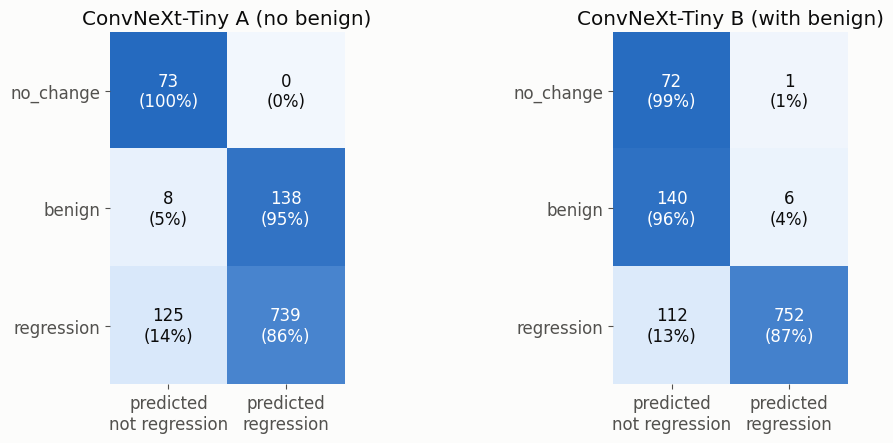

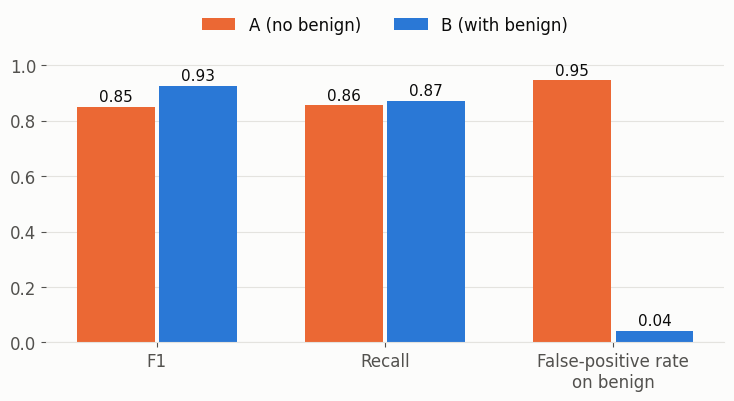

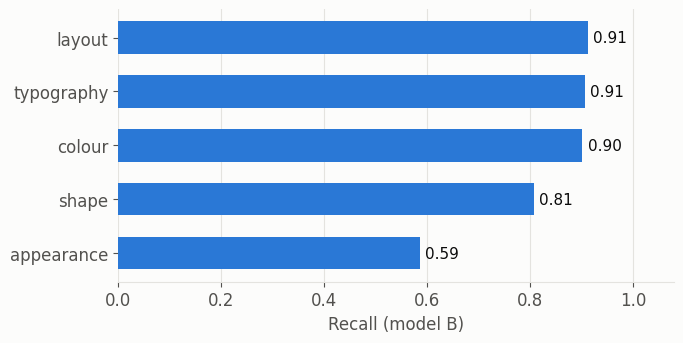

example: d2c_018_text_color | rgb(51, 51, 51) -> rgba(97, 80, 165, 1.0)


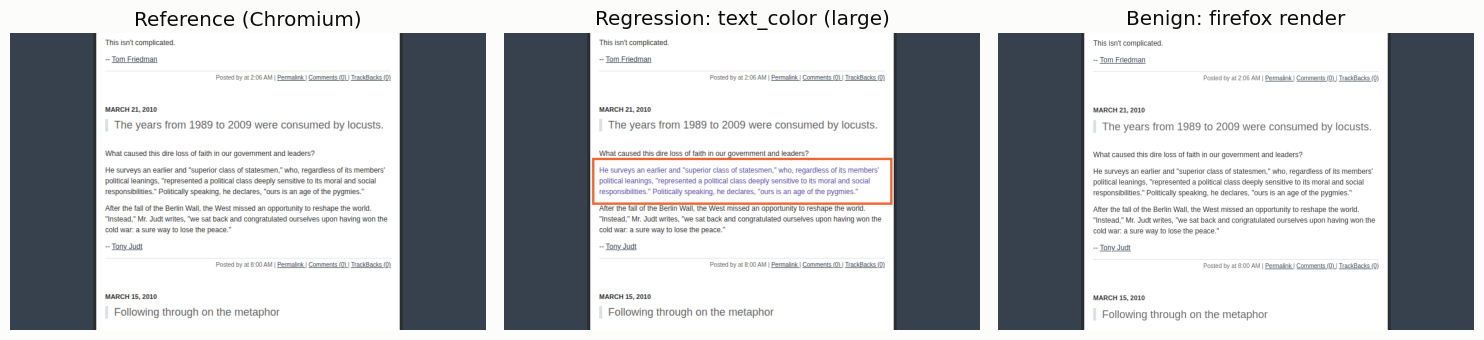

In [7]:
"""
ConvNeXt-Tiny (basic version): final numbers + slide figures.
Run AFTER the dataloader cell with INCLUDE_BENIGN = True.
Evaluates BOTH basic models on the SAME validation set (it includes benign pairs):
    A = trained without benign -> basic_convnext_A.pt
    B = trained with benign    -> basic_convnext_B.pt
"""
import os
import random

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import models
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

assert INCLUDE_BENIGN, "Set INCLUDE_BENIGN = True in the dataloader cell and rerun it first."
device = "cuda" if torch.cuda.is_available() else "cpu"

CKPT_DIR = "/content/drive/MyDrive/CSC490_data/checkpoints"
CKPTS = {"A (no benign)": "basic_convnext_A.pt",
         "B (with benign)": "basic_convnext_B.pt"}
FIG_DIR = "/content/drive/MyDrive/CSC490_data/figures"
os.makedirs(FIG_DIR, exist_ok=True)

BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK2, SURFACE, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e4e3df"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
                     "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.edgecolor": GRID, "font.size": 12})


class SiameseConvNeXt(nn.Module):
    """Must match the basic training cell that produced the checkpoints."""
    def __init__(self):
        super().__init__()
        self.trunk = models.convnext_tiny(weights=None).features
        self.fuse = nn.Sequential(
            nn.Conv2d(768 * 3, 256, 1), nn.BatchNorm2d(256), nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(inplace=True),
        )
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(512, 1))

    def forward(self, a, b):
        fa, fb = self.trunk(a), self.trunk(b)
        x = self.fuse(torch.cat([fa, fb, (fa - fb).abs()], dim=1))
        x = torch.cat([F.adaptive_avg_pool2d(x, 1), F.adaptive_max_pool2d(x, 1)], dim=1).flatten(1)
        return self.head(x).squeeze(1)


@torch.no_grad()
def predict(model, loader):
    model.eval()
    random.seed(0)  # same random tiles for the negatives -> both models see identical inputs
    probs, ids = [], []
    for b in loader:
        with torch.autocast(device_type="cuda", enabled=(device == "cuda")):
            logit = model(b["img_ref"].to(device), b["img_cand"].to(device))
        probs += torch.sigmoid(logit.float()).cpu().tolist()
        ids += list(b["sample_id"])
    return np.array(probs), ids


val_loader = DataLoader(val_ds, batch_size=8, shuffle=False, num_workers=0)
by_id = {r["sample_id"]: r for r in val_recs}
ROWS = ["no_change", "benign", "regression"]

results = {}
for name, fname in CKPTS.items():
    model = SiameseConvNeXt().to(device)
    model.load_state_dict(torch.load(os.path.join(CKPT_DIR, fname), map_location=device))
    probs, ids = predict(model, val_loader)
    pred = probs >= 0.5
    labels = np.array([by_id[s]["label"] for s in ids])

    # rows = true type, cols = [predicted not-regression, predicted regression]
    cm = np.array([[int((~pred[labels == lab]).sum()), int(pred[labels == lab].sum())] for lab in ROWS])
    tp, fn = cm[2, 1], cm[2, 0]
    fp = cm[0, 1] + cm[1, 1]
    prec, rec = tp / max(1, tp + fp), tp / max(1, tp + fn)
    fam_recall = {}
    for fam in FAMILY_MAP:
        idx = [i for i, s in enumerate(ids) if by_id[s]["label"] == "regression" and by_id[s]["family"] == fam]
        fam_recall[fam] = float(pred[idx].mean())
    results[name] = {"cm": cm, "f1": 2 * prec * rec / max(1e-9, prec + rec), "precision": prec, "recall": rec,
                     "fpr_no_change": cm[0, 1] / cm[0].sum(), "fpr_benign": cm[1, 1] / cm[1].sum(),
                     "fam_recall": fam_recall}

    print(f"\n===== ConvNeXt-Tiny {name} | validation WITH benign, threshold 0.5 =====")
    print(f"{'true type':<12}{'pred: not reg':>15}{'pred: regression':>18}")
    for lab, row in zip(ROWS, cm):
        print(f"{lab:<12}{row[0]:>15}{row[1]:>18}")

print("\n===== summary =====")
print(f"{'model':<18}{'F1':>7}{'Prec':>7}{'Recall':>8}{'FPR no_change':>15}{'FPR benign':>12}")
for name, r in results.items():
    print(f"{name:<18}{r['f1']:>7.3f}{r['precision']:>7.3f}{r['recall']:>8.3f}"
          f"{r['fpr_no_change']:>15.3f}{r['fpr_benign']:>12.3f}")

# ---------------- figure 1 (fixed): confusion matrices with two-line x labels ----------------
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list("blues", ["#f2f7fd", "#9ec5f4", "#256abf"])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, (name, r) in zip(axes, results.items()):
    cm = r["cm"]
    share = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(share, cmap=cmap, vmin=0, vmax=1)
    for i in range(3):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}\n({share[i, j]:.0%})", ha="center", va="center",
                    color="white" if share[i, j] > 0.6 else INK, fontsize=12)
    ax.set_xticks([0, 1], ["predicted\nnot regression", "predicted\nregression"])
    ax.set_yticks([0, 1, 2], ROWS)
    ax.set_title(f"ConvNeXt-Tiny {name}", color=INK)
    for s in ax.spines.values():
        s.set_visible(False)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "convnext_confusion_A_vs_B.png"), dpi=200)
plt.show()

# ---------------- figure 2: A vs B key metrics ----------------
metrics = [("F1", "f1"), ("Recall", "recall"), ("False-positive rate\non benign", "fpr_benign")]
x = np.arange(len(metrics)); w = 0.36
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for k, (name, color) in enumerate(zip(results, [ORANGE, BLUE])):
    vals = [results[name][key] for _, key in metrics]
    bars = ax.bar(x + (k - 0.5) * w, vals, w - 0.02, color=color, label=name)
    for b_, v in zip(bars, vals):
        ax.text(b_.get_x() + b_.get_width() / 2, v + 0.02, f"{v:.2f}", ha="center", color=INK, fontsize=11)
ax.set_xticks(x, [m for m, _ in metrics]); ax.set_ylim(0, 1.1)
ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
ax.legend(frameon=False, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.12))
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "convnext_A_vs_B_metrics.png"), dpi=200)
plt.show()

# ---------------- figure 3: recall per mutation family (model B) ----------------
fr = results["B (with benign)"]["fam_recall"]
fams = sorted(fr, key=fr.get)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(fams, [fr[f] for f in fams], color=BLUE, height=0.6)
for i, f in enumerate(fams):
    ax.text(fr[f] + 0.01, i, f"{fr[f]:.2f}", va="center", color=INK, fontsize=11)
ax.set_xlim(0, 1.08); ax.set_xlabel("Recall (model B)")
ax.xaxis.grid(True, color=GRID); ax.set_axisbelow(True)
for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "convnext_B_recall_by_family.png"), dpi=200)
plt.show()

# ---------------- figure 4 (redo): pick a clearly visible regression example ----------------
VISIBLE_OPS = ("background_color", "text_color", "font_size")
cands = [r for r in val_recs if r["label"] == "regression" and r["magnitude"] == "large"
         and r["operator"] in VISIBLE_OPS and r["bbox_before"][2] >= 150 and r["bbox_before"][3] >= 30]
reg = cands[0]
ben = next(r for r in val_recs if r["parent_id"] == reg["parent_id"] and r["label"] == "benign")
print("example:", reg["sample_id"], "|", reg["old_value"], "->", reg["new_value"])

x0, y0, bw, bh = reg["bbox_before"]
cx, cy = x0 + bw // 2, y0 + bh // 2
box = (max(0, cx - 400), max(0, cy - 250), max(0, cx - 400) + 800, max(0, cy - 250) + 500)

panels = []
for path, title, draw_box in [(reg["reference_path"], "Reference (Chromium)", False),
                              (reg["candidate_path"], f"Regression: {reg['operator']} ({reg['magnitude']})", True),
                              (ben["candidate_path"], f"Benign: {ben['browser_cand']} render", False)]:
    im = Image.open(os.path.join(DATA_ROOT, path)).convert("RGB")
    canvas = Image.new("RGB", (max(im.width, box[2]), max(im.height, box[3])), "white"); canvas.paste(im)
    if draw_box:
        bx, by, bww, bhh = reg["bbox_after"]
        ImageDraw.Draw(canvas).rectangle([bx - 12, by - 12, bx + bww + 12, by + bhh + 12], outline=ORANGE, width=4)
    panels.append((canvas.crop(box), title))
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (img, title) in zip(axes, panels):
    ax.imshow(img); ax.set_title(title, color=INK); ax.axis("off")
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "example_reference_regression_benign.png"), dpi=200)
plt.show()